<a href="https://colab.research.google.com/github/Andres10-cmd/aiml-pro1/blob/main/aiml2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   Experience Years  Salary
0               1.1   39343
1               1.2   42774
2               1.3   46205
3               1.5   37731
4               2.0   43525

Missing Values:
Experience Years    0
Salary              0
dtype: int64

Intercept: 26716.250176145535
Slope: 9408.03127250658

R² Score: 0.9068577573647874
Mean Squared Error: 48077731.16919359


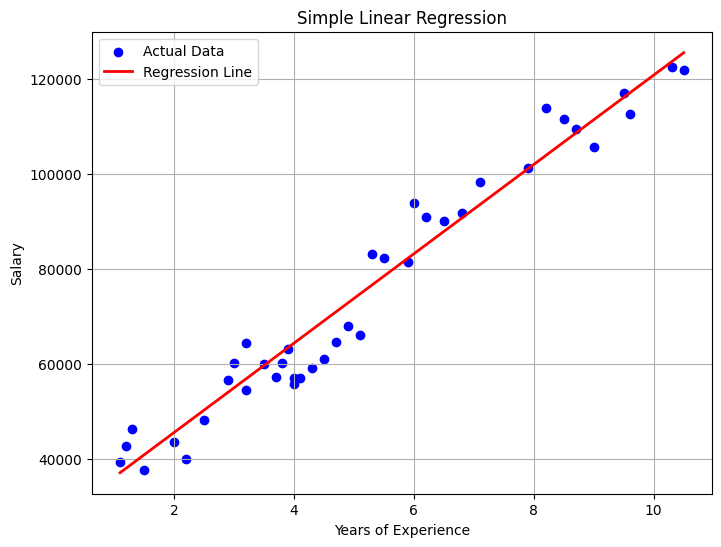

In [ ]:
 # ==========================================
# Simple Linear Regression on SalaryData.csv
# ==========================================

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 2: Load dataset
df = pd.read_csv("Salary Data.csv") # Corrected filename from 'SalaryData.csv' to 'Salary Data.csv'

# Step 3: Display first 5 rows
print(df.head())

# Step 4: Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Step 5: Select independent and dependent variables
X = df[['Experience Years']] # Corrected column name from 'YearsExperience' to 'Experience Years'
y = df['Salary']

# Step 6: Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Step 7: Create and train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 8: Make predictions
y_pred = model.predict(X_test)

# Step 9: Print regression equation
print("\nIntercept:", model.intercept_)
print("Slope:", model.coef_[0])

# Step 10: Evaluate the model
print("\nR² Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

# Step 11: Plot the regression line
plt.figure(figsize=(8,6))

# Scatter plot
plt.scatter(X, y, color='blue', label='Actual Data')

# Regression line
plt.plot(X, model.predict(X), color='red', linewidth=2, label='Regression Line')

plt.title("Simple Linear Regression")
plt.xlabel("Years of Experience")
plt.ylabel("Salary")
plt.legend()
plt.grid(True)

plt.show()

## Multivariable Linear Regression

Now, let's perform a multivariable linear regression using the `Auto.csv` dataset to predict `MPG` from multiple features.

In [ ]:
# Step 1: Load the Auto.csv dataset
df_auto = pd.read_csv('Auto.csv')

# Step 2: Handle non-numeric 'horsepower' values
df_auto['horsepower'] = pd.to_numeric(df_auto['horsepower'], errors='coerce')
df_auto.dropna(inplace=True)

# Step 3: Select multiple independent variables (features) and the dependent variable
X_multi = df_auto[['cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'year']]
y_multi = df_auto['mpg']

print("Features used for multivariable regression:")
display(X_multi.head())
print("Target variable:")
display(y_multi.head())

Features used for multivariable regression:


,cylinders,displacement,horsepower,weight,acceleration,year
0,8,307.0,130.0,3504,12.0,70
1,8,350.0,165.0,3693,11.5,70
2,8,318.0,150.0,3436,11.0,70
3,8,304.0,150.0,3433,12.0,70
4,8,302.0,140.0,3449,10.5,70


Target variable:


,mpg
0,18.0
1,15.0
2,18.0
3,16.0
4,17.0


In [ ]:
# Step 4: Split dataset into training and testing sets
X_train_multi, X_test_multi, y_train_multi, y_test_multi = train_test_split(
    X_multi, y_multi,
    test_size=0.2,
    random_state=42
)

# Step 5: Create and train the multivariable linear regression model
model_multi = LinearRegression()
model_multi.fit(X_train_multi, y_train_multi)

# Step 6: Make predictions
y_pred_multi = model_multi.predict(X_test_multi)

# Step 7: Print regression equation (coefficients and intercept)
print("\nMultivariable Linear Regression Model Parameters:")
print("Intercept:", model_multi.intercept_)
print("Coefficients:", model_multi.coef_)

# Step 8: Evaluate the model
r2_multi = r2_score(y_test_multi, y_pred_multi)
mse_multi = mean_squared_error(y_test_multi, y_pred_multi)

print("\nMultivariable Model Evaluation:")
print("R² Score:", r2_multi)
print("Mean Squared Error:", mse_multi)


Multivariable Linear Regression Model Parameters:
Intercept: -15.057758585282361
Coefficients: [-0.116173    0.00101347 -0.00227634 -0.00656101  0.06173551  0.76063644]

Multivariable Model Evaluation:
R² Score: 0.7942349075428586
Mean Squared Error: 10.502370329417325


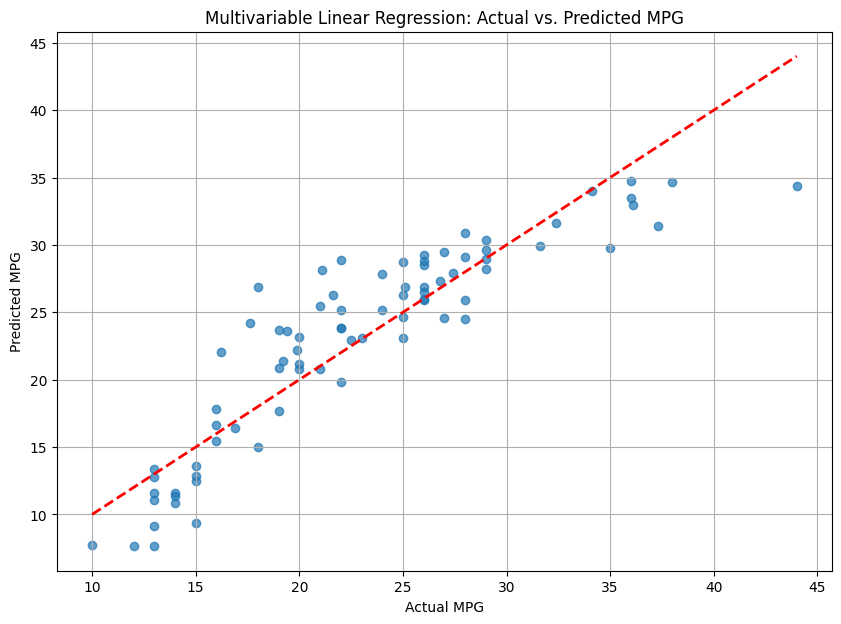

In [ ]:
# Step 9: Plot 'Actual vs. Predicted' values for multivariable regression
plt.figure(figsize=(10, 7))
plt.scatter(y_test_multi, y_pred_multi, alpha=0.7)
plt.plot([y_test_multi.min(), y_test_multi.max()], [y_test_multi.min(), y_test_multi.max()], 'r--', linewidth=2)
plt.title('Multivariable Linear Regression: Actual vs. Predicted MPG')
plt.xlabel('Actual MPG')
plt.ylabel('Predicted MPG')
plt.grid(True)
plt.show()